# River Flood Sense AI
### Flood detection for West Bengal rivers from a satellite image + weather

Give this notebook **a satellite image of a river** and **today's / tomorrow's conditions**, and it returns:

1. **Where the water is** in the image, and how much of it is *more* water than the river normally carries
2. **The probability the gauge breaches bankfull within 3 days**, from weather + river state + dam releases
3. **A fused flood probability** combining both

All data is real and downloaded from public APIs (GloFAS river discharge, ERA5 weather, Sen1Floods11 satellite imagery).

---
**Run order:** Section 0 (setup) → Section 1 (data) → Section 2-4 (models) → **Section 5 = YOUR INPUTS** → Section 6 (results).

If the models are already trained, you can jump straight from Section 0 to Section 5.

---
## 0 · Setup

In [1]:
import sys, os, json, pickle, warnings
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image

import config as C
import predict as P
from features import engineer

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25})


def require(path, build_cmd):
    """This notebook LOADS pre-built artifacts - it never trains or downloads.
    Everything is produced once by `python run_all.py`, which is why the notebook
    runs in seconds instead of an hour."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            "missing " + path.name
            + "\n  build it with:       python " + build_cmd
            + "\n  or build everything: python run_all.py")
    return path


print("project root :", ROOT)
print("torch        :", torch.__version__)
print("gauges       :", len(C.GAUGES), "  dams/barrages:", len(C.DAMS))
print("\nartifacts:")
for f, d in [("datasets/processed/flood_tabular.csv", "tabular dataset"),
             ("datasets/processed/chip_meta.csv",     "satellite chip index"),
             ("models/unet_water_ms.pt",              "U-Net multispectral"),
             ("models/unet_water_rgb.pt",             "U-Net RGB"),
             ("models/tabular_gbm.pkl",               "flood forecaster"),
             ("models/fusion.pkl",                    "fusion head")]:
    p = ROOT / f
    mark = "OK  " if p.exists() else "MISS"
    size = ("%7.1f MB" % (p.stat().st_size / 1e6)) if p.exists() else "        -"
    print("  [%s] %-24s%s" % (mark, d, size))

project root : D:\A-DS\Deep Learning\flood sense ai
torch        : 2.13.0+cpu
gauges       : 20   dams/barrages: 8

artifacts:
  [OK  ] tabular dataset            86.2 MB
  [OK  ] satellite chip index        0.1 MB
  [OK  ] U-Net multispectral         4.4 MB
  [OK  ] U-Net RGB                   7.7 MB
  [OK  ] flood forecaster            0.5 MB
  [OK  ] fusion head                 0.0 MB


---
## 1 · The data

| Source | What | Coverage |
|---|---|---|
| **GloFAS v4** (Copernicus, via Open-Meteo Flood API) | daily river discharge | 20 WB gauges + 8 dam/barrage outlets, 2005-2026 |
| **ERA5 / ERA5-Land** (via Open-Meteo Archive API) | 20 daily weather variables | same points, 2005-2026 |
| **Sen1Floods11** (Cloud to Street / NASA IMPACT) | hand-labelled Sentinel-2 flood chips | 446 chips, 11 global flood events |

**Grid snapping matters.** GloFAS uses a 0.05° river grid, so a town's nominal coordinate often lands on a minor cell. Farakka reads **2 m³/s** on its raw coordinate and **~30,000 m³/s** one cell away, so every station is snapped to its main channel.

In [2]:
snap = pd.read_csv(C.RAW_DISCHARGE / "_snap_metadata.csv")
print("Station network after GloFAS grid snapping\n")
display(snap[["name", "river", "kind", "snap_shift_km", "monsoon_mean_m3s", "record_mean_m3s"]]
        .sort_values("monsoon_mean_m3s", ascending=False)
        .style.format({"monsoon_mean_m3s": "{:,.0f}", "record_mean_m3s": "{:,.0f}"})
        .set_caption("monsoon_mean = mean discharge Jun-Oct 2019"))

Station network after GloFAS grid snapping



,name,river,kind,snap_shift_km,monsoon_mean_m3s,record_mean_m3s
0,Farakka,Ganga,gauge,6.600000,"30,089","12,362"
26,Farakka Barrage,Ganga,dam,6.600000,"30,089","12,362"
17,Jalpaiguri,Teesta,gauge,10.600000,"1,766",912
27,Gajoldoba Barrage,Teesta,dam,11.600000,"1,551",825
16,Siliguri,Mahananda,gauge,12.800000,"1,490",800
18,Cooch Behar,Torsa,gauge,17.400000,992,448
4,Kolkata,Hooghly,gauge,13.300000,716,446
11,Kolaghat,Rupnarayan,gauge,6.500000,582,420
9,Ghatal,Shilabati,gauge,14.800000,568,409
3,Nabadwip,Bhagirathi,gauge,13.800000,540,326


In [3]:
tab_path = require(C.PROC / "flood_tabular.csv", "src/build_tabular.py")
tab = pd.read_csv(tab_path, parse_dates=["date"])

print(f"rows {len(tab):,}   stations {tab.station_id.nunique()}   "
      f"{tab.date.min().date()} -> {tab.date.max().date()}")
print(f"columns {tab.shape[1]}   flood-day rate {tab.flood_next3.mean()*100:.2f}%\n")

display(tab.groupby(["station_name", "river"])
        .agg(days=("date", "size"), bankfull_m3s=("bankfull_threshold", "first"),
             flood_days=("flood_next3", "sum"))
        .assign(pct=lambda d: (d.flood_days / d.days * 100).round(1))
        .sort_values("bankfull_m3s", ascending=False)
        .style.format({"bankfull_m3s": "{:,.0f}"})
        .set_caption("bankfull = 98th percentile of that station's own GloFAS record"))

rows 157,420   stations 20   2005-01-31 -> 2026-08-19
columns 64   flood-day rate 2.78%



,,days,bankfull_m3s,flood_days,pct
station_name,river,,,,
Farakka,Ganga,7871,"52,359",201.000000,2.600000
Jalpaiguri,Teesta,7871,"3,547",225.000000,2.900000
Siliguri,Mahananda,7871,"2,984",229.000000,2.900000
Kolaghat,Rupnarayan,7871,"2,558",214.000000,2.700000
Ghatal,Shilabati,7871,"2,476",215.000000,2.700000
Kolkata,Hooghly,7871,"2,381",206.000000,2.600000
Cooch Behar,Torsa,7871,"2,036",244.000000,3.100000
Nabadwip,Bhagirathi,7871,"1,844",210.000000,2.700000
Katwa,Bhagirathi,7871,"1,485",213.000000,2.700000


### How a flood is defined

A **flood day** = GloFAS discharge exceeds that station's **bankfull proxy**, the 98th percentile of its *own* record. Per-river thresholds are essential: 2,000 m³/s is a drought on the Ganga and a catastrophe on the Ajay.

The target `flood_next3` is a breach on **any of the next 3 days** — a real short-lead forecasting task, not nowcasting.

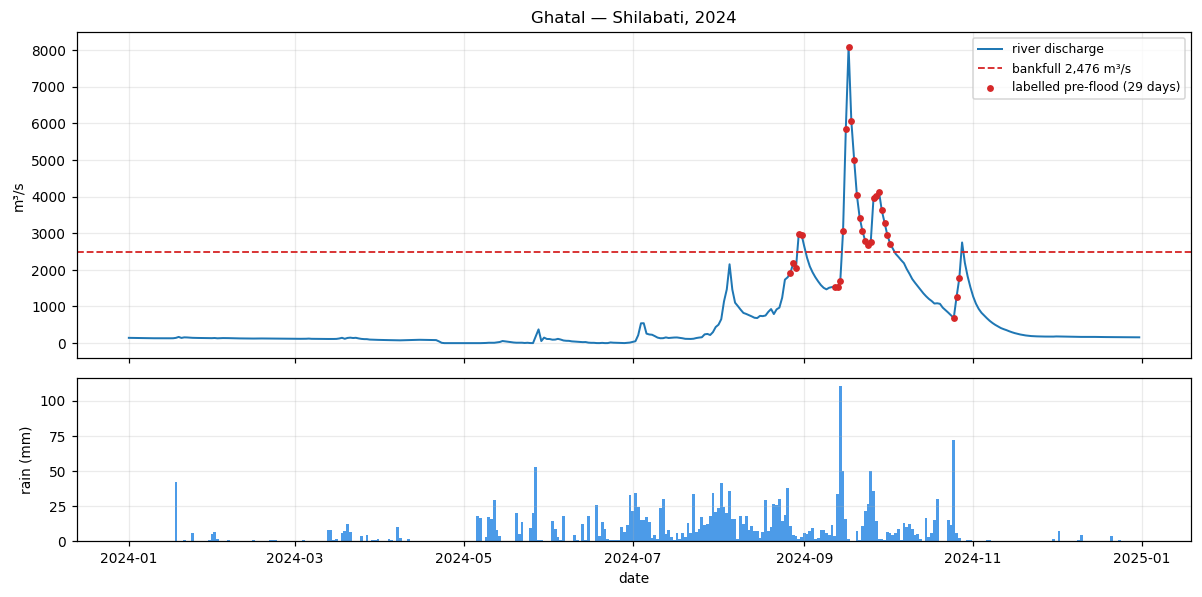

In [4]:
# 2024 monsoon at a flood-prone gauge, with the labelled pre-flood days marked.
STATION, YEAR = "ghatal_silabati", 2024
s = tab[(tab.station_id == STATION) & (tab.date.dt.year == YEAR)]
if s.empty:
    s = tab[(tab.station_id == tab.station_id.iloc[0]) & (tab.date.dt.year == YEAR)]
thr = s.bankfull_threshold.iloc[0]

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True,
                             gridspec_kw=dict(height_ratios=[2, 1]))
a1.plot(s.date, s.discharge, lw=1.3, color="#1f77b4", label="river discharge")
a1.axhline(thr, color="#d62728", ls="--", lw=1.2, label=f"bankfull {thr:,.0f} m³/s")
fl = s[s.flood_next3 == 1]
a1.scatter(fl.date, fl.discharge, s=12, color="#d62728", zorder=3,
           label=f"labelled pre-flood ({len(fl)} days)")
a1.set_ylabel("m³/s"); a1.legend(fontsize=8)
a1.set_title(f"{s.station_name.iloc[0]} — {s.river.iloc[0]}, {YEAR}")
a2.bar(s.date, s.precipitation_sum, width=1.0, color="#4c9be8")
a2.set_ylabel("rain (mm)"); a2.set_xlabel("date")
plt.tight_layout(); plt.show()

---
## 2 · Satellite branch — U-Net water segmentation

**The key idea:** flood extent = *observed water* − *the river's normal extent*. A wide river is not a flood; an **unusually** wide river is. The JRC permanent-water layer supplies that baseline during training.

Two models are trained, because two different users show up:
- **`ms`** — 7 channels: R, G, B, NIR, SWIR1 + NDWI + MNDWI. For real Sentinel-2 products.
- **`rgb`** — 3 channels of contrast-stretched true colour. For an ordinary satellite PNG/JPEG.

In [5]:
chips = pd.read_csv(C.PROC / "chip_meta.csv")
print(f"{len(chips)} usable chips, {chips.is_flooded.sum()} flooded "
      f"({chips.is_flooded.mean()*100:.1f}%)\n")
display(chips.groupby("event").agg(chips=("chip", "size"), flooded=("is_flooded", "sum"),
                                   mean_water=("water_frac", "mean"),
                                   mean_excess=("flood_frac", "mean"))
        .sort_values("chips", ascending=False).style.format("{:.3f}", subset=["mean_water", "mean_excess"]))

430 usable chips, 136 flooded (31.6%)



,chips,flooded,mean_water,mean_excess
event,,,,
USA,69,13,0.046,0.030
India,68,35,0.128,0.102
Paraguay,66,18,0.081,0.051
Sri-Lanka,42,11,0.112,0.034
Ghana,38,7,0.072,0.055
Mekong,30,13,0.236,0.160
Spain,30,9,0.142,0.078
Pakistan,28,7,0.076,0.054
Somalia,26,9,0.062,0.062


In [6]:
rows = []
for ch, label in (("ms", "multispectral: R,G,B,NIR,SWIR1,NDWI,MNDWI"),
                  ("rgb", "RGB only: an ordinary satellite picture")):
    require(C.MODELS / f"unet_water_{ch}.pt", f"src/train_cnn.py --channels {ch}")
    m = json.load(open(C.REPORTS / f"cnn_metrics_{ch}.json"))
    rows.append((ch, label, m["test_iou"], m["test_f1"], m["params"] / 1e6, m["epochs"]))

display(pd.DataFrame(rows, columns=["branch", "input", "test water IoU", "test F1",
                                    "params (M)", "epochs"])
        .style.format({"test water IoU": "{:.4f}", "test F1": "{:.4f}",
                       "params (M)": "{:.2f}"}).hide(axis="index")
        .set_caption("U-Net water segmentation, held-out chips"))

# does the predicted water fraction track the hand-labelled truth?
_c = pd.read_csv(C.PROC / "chip_meta.csv")
for ch in ("ms", "rgb"):
    col = f"pred_water_frac_{ch}"
    if col in _c:
        t = _c[_c.split == "test"]
        ind = _c[_c.event == "India"]
        print(f"{ch:3s}  water-fraction corr:  test r={t[col].corr(t.water_frac):.3f}   "
              f"Ganga/Brahmaputra r={ind[col].corr(ind.water_frac):.3f}   "
              f"MAE={abs(_c[col]-_c.water_frac).mean():.4f}")

branch,input,test water IoU,test F1,params (M),epochs
ms,"multispectral: R,G,B,NIR,SWIR1,NDWI,MNDWI",0.7351,0.8473,1.09,60
rgb,RGB only: an ordinary satellite picture,0.2113,0.3488,1.93,60


ms   water-fraction corr:  test r=0.928   Ganga/Brahmaputra r=0.994   MAE=0.0132
rgb  water-fraction corr:  test r=0.365   Ganga/Brahmaputra r=0.795   MAE=0.1395


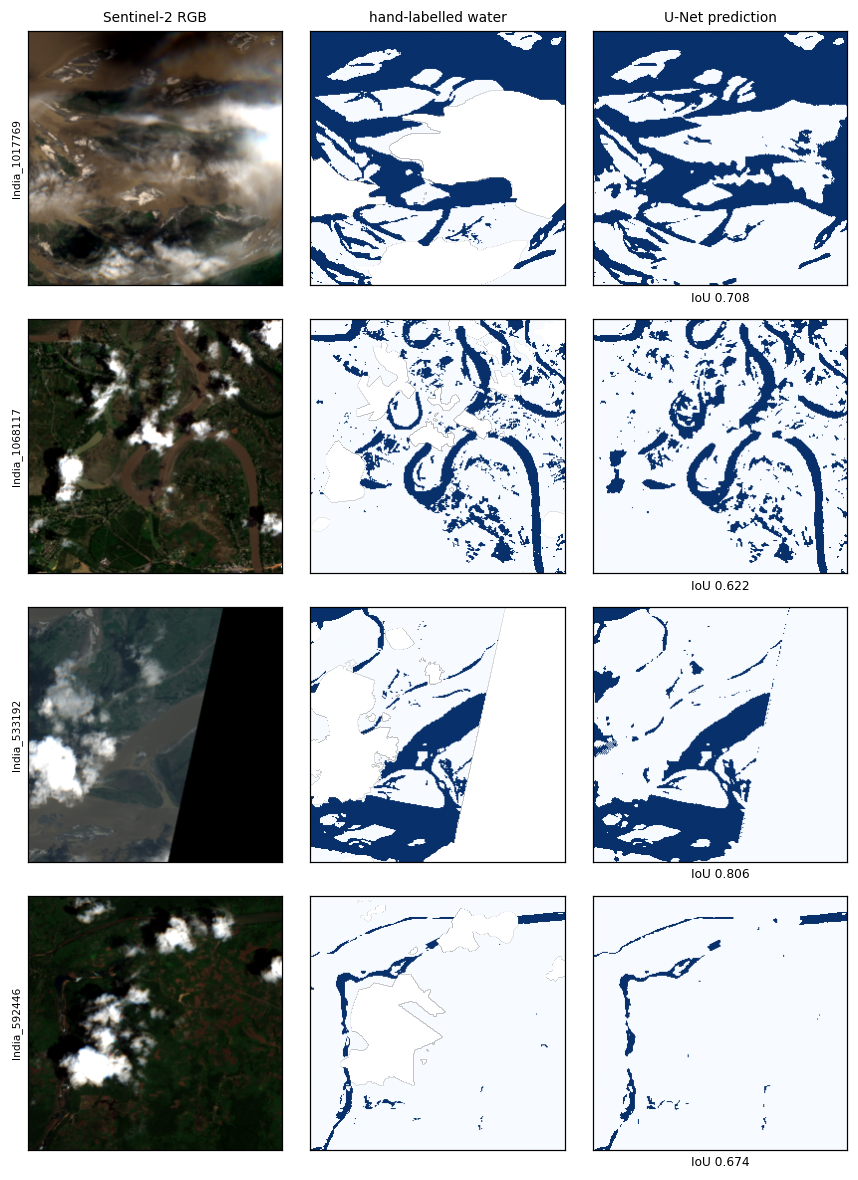

In [7]:
# image | human label | model prediction, on held-out Ganga/Brahmaputra chips.
# Arrays are memory-mapped: only the 4 displayed chips are read into RAM.
from train_cnn import UNet, spectral_indices

sel = list(chips.index[(chips.split == "test") & (chips.event == "India")][:4])
if not sel:
    sel = list(chips.index[chips.split == "test"][:4])

rgb8 = np.load(C.PROC_IMG / "RGB8.npy", mmap_mode="r")[sel]
Ymask = np.load(C.PROC_IMG / "Y.npy", mmap_mode="r")[sel]
Xsel = np.asarray(np.load(C.PROC_IMG / "X.npy", mmap_mode="r")[sel], dtype=np.float32)

ck = torch.load(C.MODELS / "unet_water_ms.pt", map_location="cpu", weights_only=False)
net = UNet(cin=ck["in_ch"], base=ck["base"]); net.load_state_dict(ck["state_dict"]); net.eval()
with torch.no_grad():
    pr = torch.sigmoid(net(spectral_indices(torch.from_numpy(Xsel)))).numpy()

fig, ax = plt.subplots(len(sel), 3, figsize=(8, 2.7 * len(sel)))
ax = np.atleast_2d(ax)
for r, idx in enumerate(sel):
    truth = np.asarray(Ymask[r])
    p = pr[r] > .5
    iou = (p & (truth == 1)).sum() / max((p | (truth == 1)).sum(), 1)
    ax[r, 0].imshow(np.asarray(rgb8[r]).transpose(1, 2, 0))
    ax[r, 1].imshow(np.ma.masked_where(truth == 255, truth), cmap="Blues", vmin=0, vmax=1)
    ax[r, 2].imshow(p, cmap="Blues", vmin=0, vmax=1)
    ax[r, 0].set_ylabel(chips.chip[idx], fontsize=7)
    ax[r, 2].set_xlabel(f"IoU {iou:.3f}", fontsize=8)
    for c in range(3):
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([]); ax[r, c].grid(False)
for c, t in enumerate(["Sentinel-2 RGB", "hand-labelled water", "U-Net prediction"]):
    ax[0, c].set_title(t, fontsize=9)
plt.tight_layout(); plt.show()

---
## 3 · Hydro-meteorological branch — 3-day flood forecast

~50 features per gauge-day, all knowable on the day of prediction:

- **today's weather** — 20 ERA5 variables
- **tomorrow's forecast** — temperature, humidity, rainfall, cloud, pressure
- **antecedent wetness** — 3/7/15/30-day rain totals, Antecedent Precipitation Index, soil-moisture memory
- **upstream catchment rain** — over the controlling reservoir
- **river state** — discharge, % of bankfull, 1/3-day rise rates
- **dam release proxy** — outflow at the controlling dam/barrage and its change
- **seasonality** — month, day-of-year harmonics, monsoon flag

> **Split is temporal, never random.** Daily river data is hugely autocorrelated — a random split leaks and reports a fake ~0.99 AUC. Train 2005-2018, validate 2019-2022, test 2023-2026.

In [8]:
require(C.MODELS / "tabular_gbm.pkl", "src/train_tabular.py")
m = json.load(open(C.REPORTS / "tabular_metrics.json"))

rows = [("Gradient boosting (all features)", m["test"]["roc_auc"], m["test"]["pr_auc"]),
        ("baseline: persistence (today's level)", m["baseline_persistence"]["roc_auc"],
         m["baseline_persistence"]["pr_auc"]),
        ("baseline: rainfall features only", m["baseline_rain_only"]["roc_auc"],
         m["baseline_rain_only"]["pr_auc"])]
display(pd.DataFrame(rows, columns=["model  (test window 2023-2026)", "ROC-AUC", "PR-AUC"])
        .style.format({"ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}"}).hide(axis="index"))

print(f"\nflood-day base rate in test window : {m['test']['base_rate']*100:.2f}%")
print(f"best F1 {m['test']['best_f1']:.3f} at p > {m['test']['best_threshold']:.3f}"
      f"   (precision {m['test']['precision_at_best']:.3f}, "
      f"recall {m['test']['recall_at_best']:.3f})")

ps = pd.read_csv(C.REPORTS / "tabular_per_station.csv")
display(ps.head(12).style.format({"roc_auc": "{:.3f}", "pr_auc": "{:.3f}",
                                  "flood_rate": "{:.3f}"}).hide(axis="index")
        .set_caption("per-station test ROC-AUC (top 12)"))

model (test window 2023-2026),ROC-AUC,PR-AUC
Gradient boosting (all features),0.9890,0.8619
baseline: persistence (today's level),0.9684,0.7938
baseline: rainfall features only,0.9144,0.2299



flood-day base rate in test window : 3.71%
best F1 0.797 at p > 0.884   (precision 0.847, recall 0.752)


station_id,station,river,n,flood_rate,roc_auc,pr_auc
farakka_ganga,Farakka,Ganga,1327,0.021,0.997,0.909
midnapore_kangsa,Midnapore,Kangsabati,1327,0.062,0.997,0.961
jalpaiguri_teesta,Jalpaiguri,Teesta,1327,0.020,0.996,0.887
udaynarayanpur,Udaynarayanpur,Damodar,1327,0.051,0.996,0.971
siliguri_mahananda,Siliguri,Mahananda,1327,0.020,0.996,0.881
burdwan_damodar,Bardhaman,Damodar,1327,0.048,0.994,0.955
berhampore_bhagi,Berhampore,Bhagirathi,1327,0.020,0.994,0.855
asansol_barakar,Asansol,Barakar,1327,0.046,0.993,0.915
gopiballavpur_sub,Gopiballavpur,Subarnarekha,1327,0.055,0.991,0.883
nabadwip_bhagi,Nabadwip,Bhagirathi,1327,0.035,0.991,0.862


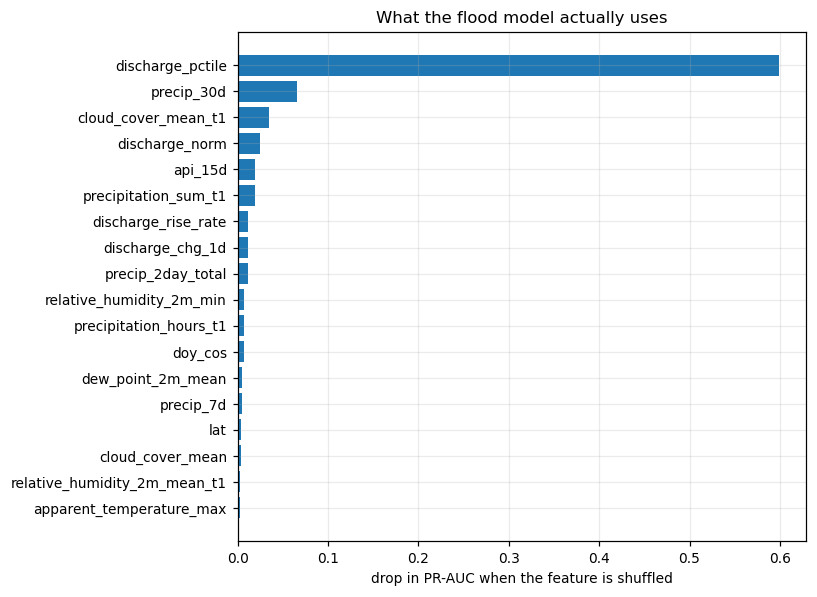

In [9]:
top = m["top_features"][:18][::-1]
plt.figure(figsize=(7.5, 5.5))
plt.barh([t[0] for t in top], [t[1] for t in top], color="#1f77b4")
plt.xlabel("drop in PR-AUC when the feature is shuffled")
plt.title("What the flood model actually uses")
plt.tight_layout(); plt.show()

---
## 4 · Fusion — does combining imagery with weather help?

Target: `is_flooded`, from the **hand-drawn** water mask minus the JRC permanent-water layer. The label comes from human annotation, not from either model. Three models, identical rows, identical split.

branch,features,ROC-AUC,PR-AUC,accuracy
image-only,3,0.9756,0.9548,0.923
hydro-only,26,0.6467,0.4930,0.615
FUSED,29,0.9733,0.9423,0.892


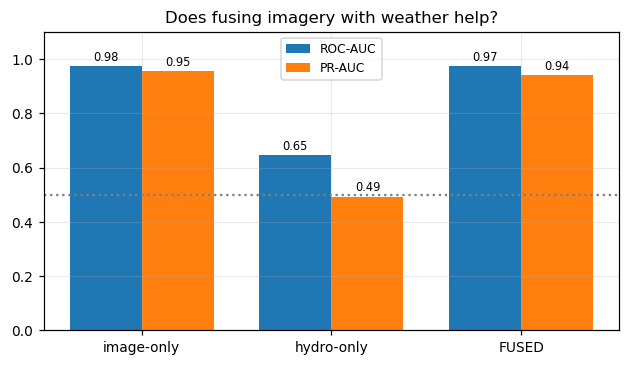

In [10]:
require(C.MODELS / "fusion.pkl", "src/train_fusion.py")
f = json.load(open(C.REPORTS / "fusion_metrics.json"))
keys = [k for k in ("image-only", "hydro-only", "FUSED") if k in f]

display(pd.DataFrame([(k, f[k]["n_features"], f[k]["roc_auc"], f[k]["pr_auc"], f[k]["accuracy"])
                      for k in keys],
                     columns=["branch", "features", "ROC-AUC", "PR-AUC", "accuracy"])
        .style.format({"ROC-AUC": "{:.4f}", "PR-AUC": "{:.4f}", "accuracy": "{:.3f}"})
        .hide(axis="index")
        .set_caption("target = hand-labelled is_flooded; image branch = " + f["image_column"]))

x = np.arange(len(keys)); w = .38
plt.figure(figsize=(5.8, 3.4))
plt.bar(x - w/2, [f[k]["roc_auc"] for k in keys], w, label="ROC-AUC", color="#1f77b4")
plt.bar(x + w/2, [f[k]["pr_auc"] for k in keys], w, label="PR-AUC", color="#ff7f0e")
for i, k in enumerate(keys):
    plt.text(i - w/2, f[k]["roc_auc"] + .02, f"{f[k]['roc_auc']:.2f}", ha="center", fontsize=7.5)
    plt.text(i + w/2, f[k]["pr_auc"] + .02, f"{f[k]['pr_auc']:.2f}", ha="center", fontsize=7.5)
plt.xticks(x, keys); plt.ylim(0, 1.10); plt.axhline(.5, color="grey", ls=":")
plt.title("Does fusing imagery with weather help?"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# 5 · YOUR INPUTS  ⬅️ *edit this cell*

Set the satellite image and the conditions, then run Section 6.

- **`IMAGE`** — path to a satellite image. `.png` / `.jpg` uses the RGB model; a 13-band Sentinel-2 `.tif` uses the multispectral model. Set to `None` to skip the image branch.
- **`USE_LIVE_WEATHER = True`** — fetch today's real weather + river discharge for the station, then apply any override you set below.
- **`USE_LIVE_WEATHER = False`** — use only the numbers you type (antecedent rainfall and river state still come from the historical record).

In [11]:
# ========================= YOUR INPUTS =========================

STATION = "ghatal_silabati"        # full list printed below

# Which satellite image to analyse.
#   *.tif  13-band Sentinel-2  -> uses the MULTISPECTRAL model (much more accurate)
#   *.png / *.jpg              -> uses the RGB model
#   None                       -> skip the image branch entirely
IMAGE = str(sorted((C.RAW_SAT / "S2Hand").glob("India_*_S2Hand.tif"))[0])
# IMAGE = str(sorted((C.PROC_IMG / "preview").glob("India_*.png"))[0])   # RGB branch
# IMAGE = r"C:\path\to\my_ganga_image.png"
# IMAGE = None

USE_LIVE_WEATHER = True            # False = replay the historical record, no network

# --- today ---
TEMP_MAX_TODAY     = 33.0    # deg C
TEMP_MIN_TODAY     = 26.0    # deg C
HUMIDITY_TODAY     = 88.0    # %
RAINFALL_TODAY     = 120.0   # mm

# --- tomorrow's forecast ---
TEMP_MAX_TOMORROW  = 31.0    # deg C
TEMP_MIN_TOMORROW  = 25.5    # deg C
HUMIDITY_TOMORROW  = 92.0    # %
RAINFALL_TOMORROW  = 150.0   # mm

# --- upstream dam release, m3/s (None = leave at the observed value) ---
DAM_OUTFLOW        = None

# --- how much of the IMAGE is water even in a normal year, 0-1 ---
#     None = use the JRC-derived dataset default
NORMAL_RIVER_COVER = None

# ===============================================================
print(f"image  : {Path(IMAGE).name if IMAGE else 'none'}")
print(f"station: {STATION}\n")
print("Available gauges:")
for g in C.GAUGES:
    mark = "   <== selected" if g["id"] == STATION else ""
    print(f"  {g['id']:<22} {g['name']:<15} {g['river']:<13} {g['district']}{mark}")

image  : India_1017769_S2Hand.tif
station: ghatal_silabati

Available gauges:
  farakka_ganga          Farakka         Ganga         Murshidabad
  berhampore_bhagi       Berhampore      Bhagirathi    Murshidabad
  katwa_bhagirathi       Katwa           Bhagirathi    Purba Bardhaman
  nabadwip_bhagi         Nabadwip        Bhagirathi    Nadia
  kolkata_hooghly        Kolkata         Hooghly       Kolkata
  burdwan_damodar        Bardhaman       Damodar       Purba Bardhaman
  udaynarayanpur         Udaynarayanpur  Damodar       Howrah
  asansol_barakar        Asansol         Barakar       Paschim Bardhaman
  ilambazar_ajay         Ilambazar       Ajay          Birbhum
  ghatal_silabati        Ghatal          Shilabati     Paschim Medinipur   <== selected
  midnapore_kangsa       Midnapore       Kangsabati    Paschim Medinipur
  kolaghat_rupnaraya     Kolaghat        Rupnarayan    Purba Medinipur
  bankura_dwarakesw      Bankura         Dwarakeswar   Bankura
  gopiballavpur_sub      Gopi

---
# 6 · Results

In [12]:
import importlib; importlib.reload(P)

overrides = dict(temp_max_today=TEMP_MAX_TODAY, temp_min_today=TEMP_MIN_TODAY,
                 humidity_today=HUMIDITY_TODAY, rain_today=RAINFALL_TODAY,
                 temp_max_tomorrow=TEMP_MAX_TOMORROW, temp_min_tomorrow=TEMP_MIN_TOMORROW,
                 humidity_tomorrow=HUMIDITY_TOMORROW, rain_tomorrow=RAINFALL_TOMORROW,
                 dam_outflow=DAM_OUTFLOW)

if USE_LIVE_WEATHER:
    print("fetching live weather + GloFAS discharge …")
    live = P.fetch_live(STATION)
else:
    # replay the historical record instead of calling the network
    st = C.ALL_POINTS[STATION]; up = st.get("upstream")
    rd = lambda f, s: pd.read_csv(f / f"{s}.csv", parse_dates=["date"]).tail(400)
    live = dict(weather=rd(C.RAW_WEATHER, STATION), discharge=rd(C.RAW_DISCHARGE, STATION),
                up_weather=rd(C.RAW_WEATHER, up) if up else None,
                up_discharge=rd(C.RAW_DISCHARGE, up) if up else None, station=st)

row, feat, bankfull = P.build_row(live, overrides=overrides)
st = C.ALL_POINTS[STATION]

print(f"\n{'='*66}")
print(f"  {st['name']} — {st['river']}, {st['district']}")
print(f"  {pd.Timestamp(row['date']).date()}   bankfull {bankfull:,.0f} m³/s")
print(f"{'='*66}")

inputs = [
    ("Temperature today",        f"{row['temperature_2m_max']:.1f} / {row['temperature_2m_min']:.1f} °C"),
    ("Temperature tomorrow",     f"{row['temperature_2m_max_t1']:.1f} / {row['temperature_2m_min_t1']:.1f} °C"),
    ("Humidity today",           f"{row['relative_humidity_2m_mean']:.0f} %"),
    ("Humidity tomorrow",        f"{row['relative_humidity_2m_mean_t1']:.0f} %"),
    ("Rainfall today",           f"{row['precipitation_sum']:.1f} mm"),
    ("Rainfall tomorrow",        f"{row['precipitation_sum_t1']:.1f} mm"),
    ("Rain last 7 / 30 days",    f"{row['precip_7d']:.0f} / {row['precip_30d']:.0f} mm"),
    ("Antecedent index (API)",   f"{row['api_15d']:.0f} mm"),
    ("Deep soil moisture",       f"{row['soil_moisture_0_to_100cm_mean']:.3f} m³/m³"),
    ("River discharge",          f"{row['discharge']:,.0f} m³/s  ({row['discharge_norm']*100:.0f}% of bankfull)"),
    ("River rise, 3 days",       f"{row['discharge_chg_3d']:+,.0f} m³/s"),
]
if row.get("has_upstream_dam"):
    inputs.append(("Upstream dam outflow", f"{row['dam_outflow']:,.0f} m³/s "
                                           f"({row['dam_outflow_chg_1d']:+,.0f} in 24h)"))
if pd.notna(row.get("upstream_precip_3d")):
    inputs.append(("Upstream catchment rain 3d", f"{row['upstream_precip_3d']:.0f} mm"))
display(pd.DataFrame(inputs, columns=["Input", "Value"]).style.hide(axis="index")
        .set_caption("Conditions fed to the model"))

fetching live weather + GloFAS discharge …


RuntimeError: failed after 6 tries: https://api.open-meteo.com/v1/forecast?latitude=22.665&longitude=87.727&timezone=Asia%2FKolkata&daily=temperature_2m_max,temperature_2m_min,
last error: URLError: <urlopen error [Errno 11001] getaddrinfo failed>

In [ ]:
# ---- image branch -------------------------------------------------------------
water_frac = perm = None
if IMAGE:
    x, mode, disp = P.prepare_image(IMAGE)
    unet = P.load_unet(mode)
    prob, water_frac = P.segment_water(unet, x)
    perm = NORMAL_RIVER_COVER if NORMAL_RIVER_COVER is not None else P.DEFAULT_PERM_WATER
    excess = max(0.0, water_frac - perm)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4.2))
    ax[0].imshow(disp);                       ax[0].set_title(f"input ({mode} branch)")
    ax[1].imshow(prob, cmap="Blues", vmin=0, vmax=1); ax[1].set_title("water probability")
    ax[2].imshow(P.overlay(disp, prob));      ax[2].set_title("detected water")
    for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
    plt.tight_layout(); plt.show()

    verdict = ("FLOODING VISIBLE" if excess > C.FLOOD_FRAC_THRESHOLD
               else "river within its normal extent")
    display(pd.DataFrame([
        ("Water in scene",       f"{water_frac*100:.1f} %"),
        ("Normal river extent",  f"{perm*100:.1f} %"),
        ("Excess water",         f"{excess*100:.1f} %   <- flood signal"),
        ("Image verdict",        verdict),
    ], columns=["Image measurement", "Value"]).style.hide(axis="index"))
else:
    print("no image supplied — image branch skipped")

In [ ]:
# ---- final assessment ----------------------------------------------------------
p_tab, _ = P.tabular_probability(row)
p_fus = P.fusion_probability(row, water_frac, perm) if water_frac is not None else None
band, note = P.risk_band(p_tab)
icon = {"SEVERE": "🔴", "HIGH": "🟠", "WATCH": "🟡", "LOW": "🟢", "unknown": "⚪"}[band]

print(f"\n{'='*66}")
print(f"  FLOOD ASSESSMENT — {st['name']} ({st['river']})")
print(f"{'='*66}")
if p_tab is not None:
    print(f"  {icon} 3-day bankfull-breach probability : {p_tab*100:5.1f} %   [{band}]")
    print(f"       {note}")
if p_fus is not None:
    print(f"  🛰  fused flood probability (image+met) : {p_fus*100:5.1f} %")
if water_frac is not None:
    print(f"  💧 visible inundation above normal     : {max(0.0, water_frac-perm)*100:5.1f} %")
print(f"{'='*66}\n")

vals = [p for p in (p_tab, p_fus) if p is not None]
if vals:
    labels = (["3-day breach\nforecast"] if p_tab is not None else []) + \
             (["fused flood\nprobability"] if p_fus is not None else [])
    plt.figure(figsize=(5.2, 3.2))
    cols = ["#d62728" if v >= .7 else "#ff7f0e" if v >= .45 else
            "#e8c33a" if v >= .2 else "#2ca02c" for v in vals]
    plt.bar(labels, [v*100 for v in vals], color=cols, width=.55)
    for i, v in enumerate(vals):
        plt.text(i, v*100 + 2, f"{v*100:.1f}%", ha="center", fontweight="bold")
    for y, lab in ((20, "watch"), (45, "high"), (70, "severe")):
        plt.axhline(y, color="grey", ls=":", lw=.8)
        plt.text(len(vals)-.4, y+1, lab, fontsize=7, color="grey")
    plt.ylim(0, 108); plt.ylabel("probability (%)")
    plt.title(f"{st['name']} — {pd.Timestamp(row['date']).date()}")
    plt.tight_layout(); plt.show()

---
## 7 · Scenario testing

Sweep rainfall and dam release to see how the model responds — a quick sanity check that it learned physics rather than noise.

In [ ]:
rain_grid = [0, 25, 50, 100, 150, 200, 300]
dam_grid = ([None] if not row.get("has_upstream_dam")
            else [row["dam_outflow"], row["dam_outflow"] * 3, row["dam_outflow"] * 8])

plt.figure(figsize=(7, 4))
for dv in dam_grid:
    ps = []
    for r in rain_grid:
        ov = {**overrides, "rain_today": r, "rain_tomorrow": r, "dam_outflow": dv}
        rr, _, _ = P.build_row(live, overrides=ov)
        ps.append(P.tabular_probability(rr)[0] * 100)
    lab = "no upstream dam" if dv is None else f"dam outflow {dv:,.0f} m³/s"
    plt.plot(rain_grid, ps, marker="o", label=lab)
plt.xlabel("rainfall today = tomorrow (mm)")
plt.ylabel("3-day flood probability (%)")
plt.title(f"Model response at {st['name']} ({st['river']})")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

---
## 8 · Honest limits

Things a reviewer should know before trusting any number above:

- **Dam releases are a proxy.** DVC and Farakka publish cusec figures in press bulletins, not through any open API. The "dam outflow" feature is GloFAS discharge at the reservoir outlet cell — it tracks release behaviour but is not the operator's logged release.
- **GloFAS is a global model.** It represents the Bhagirathi–Hooghly distributaries and the tidal lower Damodar poorly, because flow there is split by barrage operation a global model does not know. That is exactly why labels are exceedances of each station's *own* high quantile rather than absolute cumec values.
- **Flood labels are threshold exceedances, not surveyed inundation.** No open daily district-level inundation record exists for West Bengal.
- **The satellite model is trained on global flood imagery.** Sen1Floods11's Indian event is the 2016 Brahmaputra flood in Assam — the closest hand-labelled monsoon analogue, but not West Bengal itself.
- **Tomorrow's "forecast" is tomorrow's reanalysis during training** — an optimistic stand-in, so live performance with a real IMD forecast would be somewhat worse.
- **The permanent-water baseline is user-supplied at inference.** Training uses the JRC layer; for an arbitrary uploaded image you set `NORMAL_RIVER_COVER`.

**This is a portfolio/educational demo, not an operational warning system.** For real warnings use the [WB Irrigation & Waterways Department](https://wbiwd.gov.in/) and IMD bulletins.